<a href="https://colab.research.google.com/github/saketh-varma06/DL_ASSIGNMENTS/blob/main/DL_ASS3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Dataset Shape: (1025, 14)

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Training Data: torch.Size([820, 13])
Testing Data: torch.Size([205, 13])

Model:
HeartDiseaseModel(
  (network): 

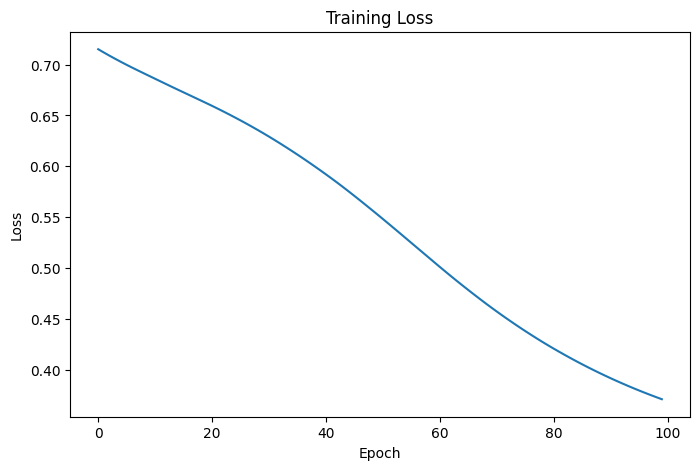

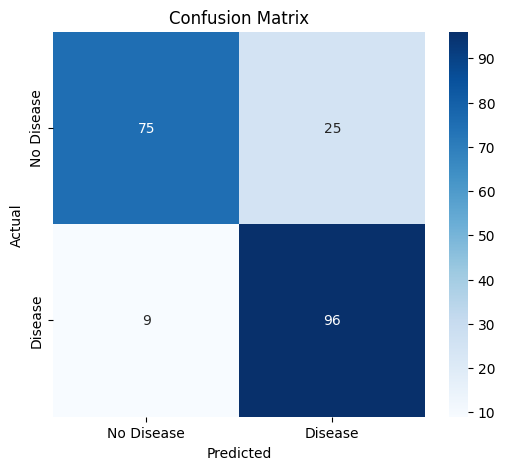


========== CONCLUSION ==========

The Heart Disease dataset was successfully loaded and
preprocessed. A feed-forward neural network was developed
using PyTorch and trained using the Adam optimizer and
Binary Cross Entropy loss. The model achieved good
classification performance based on accuracy, precision,
recall and F1-score. The training loss graph showed the
learning behavior of the model, while the confusion matrix
showed the correct and incorrect predictions. Overall, the
PyTorch model performed well in predicting heart disease.



In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# =========================================================
# TASK 1: LOAD AND PREPROCESS DATA
# =========================================================

df = pd.read_csv("heart.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

# Features and target
X = df.drop("target", axis=1)
y = df["target"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardization
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(
    y_train.values,
    dtype=torch.float32
).reshape(-1, 1)

y_test = torch.tensor(
    y_test.values,
    dtype=torch.float32
).reshape(-1, 1)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# =========================================================
# TASK 2: BUILD PYTORCH MODEL
# =========================================================

class HeartDiseaseModel(nn.Module):

    def __init__(self):
        super(HeartDiseaseModel, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(13, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)


model = HeartDiseaseModel()

print("\nModel:")
print(model)


# =========================================================
# TASK 3: TRAIN MODEL
# =========================================================

criterion = nn.BCELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100

losses = []

for epoch in range(epochs):

    # Forward pass
    outputs = model(X_train)

    # Loss
    loss = criterion(outputs, y_train)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )


# =========================================================
# TASK 4: EVALUATION
# =========================================================

with torch.no_grad():

    outputs = model(X_test)

    predictions = (outputs >= 0.5).float()


y_true = y_test.numpy()
y_pred = predictions.numpy()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("\n========== MODEL PERFORMANCE ==========")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))


# =========================================================
# TASK 5: VISUALIZATION
# =========================================================

# Training Loss
plt.figure(figsize=(8, 5))

plt.plot(losses)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()


# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


# =========================================================
# TASK 6: CONCLUSION
# =========================================================

print("\n========== CONCLUSION ==========")

print("""
The Heart Disease dataset was successfully loaded and
preprocessed. A feed-forward neural network was developed
using PyTorch and trained using the Adam optimizer and
Binary Cross Entropy loss. The model achieved good
classification performance based on accuracy, precision,
recall and F1-score. The training loss graph showed the
learning behavior of the model, while the confusion matrix
showed the correct and incorrect predictions. Overall, the
PyTorch model performed well in predicting heart disease.
""")